# LSTM soil-moisture forecast, 72h horizon (FD11)

Forecasts `SWC_20` (soil water content at 20 cm) at station `FD11` **72 hours** after the end of a 24-hour input
window with a small LSTM, and compares it with the naive baselines (last value, 24h moving average). There is no
feature selection and no hyperparameter grid: one engineered feature set and one fixed configuration, checked with
time-series cross-validation.

**Pipeline:** load → rain-gauge check → feature engineering → feature check → year split → scaling → windows →
LSTM → time-series CV check → final train → evaluation.

| | |
|---|---|
| Data | `TxSON33_modeling_complete.parquet`, station `FD11`, hourly, five calendar years: 2019, 2020, 2021, 2022, 2024 |
| Skipped | 2023: the `FD11` rain gauge recorded no rain from 2022-12-04 to 2023-09-24 (Section 2) |
| Split | train 2019–2021, validation 2022 (early stopping only), test 2024 (used once, at the end) |
| Lookback / horizon | 24 hours / 72 hours: inputs cover hours `[t, t+23]`, the target is `SWC_20` at `t + 23 + 72` |
| Network output | the change in `SWC_20` from the window's last hour to the target hour, added back to that last value; every score is in `SWC_20` units, on `observed` readings only |
| Inputs | 11 engineered hourly features in three groups: soil state at 20 cm, the 5 cm sensor, rain memory (Section 3) |
| Loss | Huber, δ = 0.005 `SWC_20` (Section 9) |
| Model (fixed) | LSTM, 1 layer, hidden size 32, Adam lr 0.001, batch size 16, up to 30 epochs, early stopping patience 10 |
| CV check | `TimeSeriesSplit` over the training years (train 2019 → validate 2020; train 2019–2020 → validate 2021): inputs {2 earlier, 11 engineered} × loss {MSE, Huber} |
| Baselines | last value (persistence) and 24h moving average, on exactly the same targets |

### Why this design

1. **Most of persistence's 72h error cannot be forecast.** In about a quarter of the hours, at least 2 mm of rain
   falls in the 72 hours between the input window and the target, and those windows carry about 83% of
   persistence's squared error in the training years (Section 4). A model that only sees the past cannot anticipate that rain. What it
   *can* forecast is the rest: the steady drydown (a median −0.006 per 72 hours without rain, which persistence
   predicts as 0) and the fast recession right after a wetting peak.
2. **An MSE loss chases the unforecastable rain.** The 72h change is skewed: the median is −0.005, but a long
   tail of rain jumps reaching +0.25 pulls the mean up to −0.0003. MSE pulls the forecast toward the mean, so in dry spells the model
   sits above the actual drydown, as if hedging for rain. That is the persistent high bias and the
   worse-than-persistence MAE of the earlier runs. A Huber loss with a small δ treats the rain jumps linearly, so
   the forecast follows the typical outcome.
3. **A 24-hour window forgets.** The drydown rate, the time since the last storm and the storm's total depth need
   more than 24 hours of history. The engineered features carry up to 30 days of it into every hour of the window.
4. **2023's rain record is broken** (Section 2), so it is not used for training, early stopping or testing.

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
# --- Setup and reproducibility ---
import json
import os
import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import TimeSeriesSplit

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

# Same folder as this notebook. In Colab, upload the parquet (or mount Drive) and point this at it.
PARQUET_PATH = "/content/drive/MyDrive/TxSON33_modeling_complete.parquet"
STATION = "FD11"
# Five calendar years, chronological. 2023 is skipped: FD11's rain gauge recorded nothing from 2022-12-04 to
# 2023-09-24 (Section 2).
TRAIN_YEARS = [2019, 2020, 2021]   # fits the model; the time-series CV check runs inside these years
VAL_YEARS = [2022]                 # early stopping of the final model only
TEST_YEARS = [2024]                # touched once, at the end
SKIPPED_YEARS = [2023]
MODEL_YEARS = TRAIN_YEARS + VAL_YEARS + TEST_YEARS
N_CV_SPLITS = 2                    # TimeSeriesSplit over TRAIN_YEARS: 2019 -> 2020, 2019-2020 -> 2021

TARGET_COL = "SWC_20"
WINDOW_SIZE = 24                   # hours of past data used as input
HORIZON = 72                       # target = SWC_20 this many hours after the window's last hour
PPT_DEADBAND_MM = 1.0              # hourly rainfall below this (mm) is set to 0 before every rainfall feature
API_DECAY_PER_HOUR = 0.98          # antecedent precipitation index: hourly decay (half-life about 34 hours)
HOURS_SINCE_RAIN_CAP = 720         # hours since rain is capped at 30 days

BASE_FEATURES = ["SWC_20", "Ppt_rolling_24h_log"]   # the earlier notebooks' inputs, for the CV check only
FEATURE_GROUPS = {
    "soil state at 20 cm": ["SWC_20", "SWC_20_change_24h", "SWC_20_change_72h",
                            "SWC_20_below_max_72h", "SWC_20_above_min_30d"],
    "5 cm sensor": ["SWC_5"],
    "rain memory": ["Ppt_rolling_24h_log", "Ppt_rolling_72h_log", "Ppt_rolling_168h_log",
                    "hours_since_rain_log", "api_log"],
}
FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]   # the model inputs (11)

# Fixed model configuration (no grid search)
MODEL_CONFIG = {"hidden_size": 32, "num_layers": 1, "lr": 0.001, "batch_size": 16}
LOSS = "huber"                     # "huber" or "mse"
HUBER_DELTA = 0.005                # SWC_20 units: errors larger than this are penalized linearly, not squared
EPOCHS = 30                        # max epochs, every fit (CV and final)
PATIENCE = 10                      # early stopping: stop after 10 epochs without validation improvement
EVAL_BATCH_SIZE = 1024             # validation losses and predictions only (speed; training batches stay 16)
# Evaluation only, never inputs
GAP_RAIN_MM = 2.0                  # a window "has gap rain" if >= 2 mm falls between its last hour and its target
RISE_FORECAST_MIN = 0.02           # a forecast rise above this ...
RISE_ACTUAL_MAX = 0.005            # ... is a false rise if SWC_20 actually rose by less than this
# CV fits are independent and seeded the same way: one at a time on a GPU, up to 4 single-threaded CPU workers
N_JOBS = 1 if DEVICE.type == "cuda" else min(4, os.cpu_count() or 1)

# Plot colors: actual = ink, model = blue, last-value baseline = orange, reference lines = gray
C_ACTUAL, C_MODEL, C_LAST, C_MUTED = "#0b0b0b", "#2a78d6", "#eb6834", "#8a8984"

# CV table, test metrics and the run summary are saved here.
# In Colab, point this at a mounted Drive folder (e.g. "/content/drive/MyDrive/txson_outputs") to keep the files.
OUTPUT_DIR = "outputs_lstm_72h"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def output_path(name):
    return os.path.join(OUTPUT_DIR, f"{STATION}_h{HORIZON}_{name}")

device: cuda


## 1. Load the data

The full `FD11` history is kept on a complete hourly grid: the engineered features look back up to 30 days, so
they are computed on the history (Section 3) and only then cut to the five modeling years. The `*_Origin` columns
say whether each value is `observed`, `pipeline_imputed` or synthetic `modeling_completion`.

In [12]:
raw = pd.read_parquet(PARQUET_PATH)
raw["Timestamp"] = pd.to_datetime(raw["Timestamp"])

# Full FD11 history, sorted, on a complete hourly grid (asfreq would add a NaN row for any missing hour)
station_df = raw[raw["Station"] == STATION].sort_values("Timestamp").set_index("Timestamp")
assert not station_df.index.duplicated().any(), "duplicate timestamps"
n_rows = len(station_df)
station_df = station_df.asfreq("h")
print(f"{STATION} history: {station_df.index.min()} -> {station_df.index.max()}, {len(station_df)} hourly rows "
      f"({len(station_df) - n_rows} missing hours added)")

RAW_INPUT_COLS = ["SWC_20", "SWC_5", "Ppt"]
ORIGINS = ["observed", "pipeline_imputed", "modeling_completion"]
model_rows = station_df[station_df.index.year.isin(MODEL_YEARS)]
print(f"Modeling years {MODEL_YEARS}: {len(model_rows)} rows")
print("Missing values in the raw inputs, whole history:", station_df[RAW_INPUT_COLS].isna().sum().to_dict())
print()
print("Origin of each raw input in the modeling years (modeling_completion = synthetic):")
print(pd.DataFrame({c: model_rows[f"{c}_Origin"].value_counts() for c in RAW_INPUT_COLS}).T
      .reindex(columns=ORIGINS).fillna(0).astype(int).to_string())
print("Hours where the target is not an observed reading:",
      [str(t) for t in model_rows.index[model_rows[f"{TARGET_COL}_Origin"] != "observed"]])
print()
# Resolution check: a sensor with only a handful of distinct values steps instead of varying smoothly
print("Distinct values in the modeling years:", {c: model_rows[c].nunique() for c in ["SWC_20", "SWC_5", "SWC_10"]})
print(f"SWC_10 range: {model_rows['SWC_10'].min():.3f} to {model_rows['SWC_10'].max():.3f} "
      f"(SWC_5: {model_rows['SWC_5'].min():.3f} to {model_rows['SWC_5'].max():.3f})")

FD11 history: 2014-11-12 18:00:00 -> 2025-07-16 15:00:00, 93574 hourly rows (0 missing hours added)
Modeling years [2019, 2020, 2021, 2022, 2024]: 43848 rows
Missing values in the raw inputs, whole history: {'SWC_20': 0, 'SWC_5': 0, 'Ppt': 0}

Origin of each raw input in the modeling years (modeling_completion = synthetic):
        observed  pipeline_imputed  modeling_completion
SWC_20     43846                 2                    0
SWC_5      43846                 2                    0
Ppt        43847                 1                    0
Hours where the target is not an observed reading: ['2019-10-24 16:00:00', '2019-11-18 12:00:00']

Distinct values in the modeling years: {'SWC_20': 277, 'SWC_5': 302, 'SWC_10': 4}
SWC_10 range: 0.001 to 0.004 (SWC_5: 0.126 to 0.431)


**What this shows:** the `FD11` history runs from 2014-11-12 18:00 to 2025-07-16 15:00 with no missing hours and
no missing values. In the five modeling years (43,848 hours), the raw inputs are `observed` except for 2
`pipeline_imputed` hours each in `SWC_20` and `SWC_5` (both in 2019) and 1 in `Ppt`; nothing used here is
synthetic. The two non-observed `SWC_20` hours (2019-10-24 16:00, 2019-11-18 12:00) are never used as targets
(Section 7). `SWC_10` takes only four distinct values, 0.001 to 0.004, against hundreds for `SWC_5` and `SWC_20`.
It is stored about 100× too small and rounded to three decimals, so it is not used (Section 3).

## 2. Rain-gauge check: why 2023 is skipped

`FD11`'s `Ppt` is flagged `observed` throughout, but the gauge recorded **no rain at all from 2022-12-04 to
2023-09-24**. That is 294 days in a row; the next-longest dry run in its history (2014–2025) is 46 days. In 2023 the
gauge recorded about 200 mm against a regional median of about 520 mm (most other TxSON stations recorded 470–580 mm). The soil shows the missing rain
anyway. Below, a *wetting event* is `SWC_5` rising by more than 0.05 within 6 hours, and an event with less than
1 mm of recorded rain within ±24 hours is one the gauge missed.

A model trained or early-stopped on 2023 would see the soil wet up with no rain as input and learn that the rain
inputs do not matter, so 2023 is not used. The last four weeks of the validation year (from 2022-12-04) fall inside
the outage; regional rainfall that December was only about 6 mm, so 2022 is kept whole. By 2024 the gauge has been
working again for three months, longer than any feature's lookback.

Longest runs with no recorded rain:
  2022-12-04 13:00:00 -> 2023-09-24 18:00:00: 294 days
  2016-01-06 21:00:00 -> 2016-02-21 18:00:00: 46 days
  2024-09-23 13:00:00 -> 2024-11-02 03:00:00: 40 days

      recorded_rain_mm  wetting_events  events_with_no_recorded_rain      use
year                                                                         
2014                47               1                             0         
2015               786              33                             0         
2016               851              26                             0         
2017               534              16                             2         
2018               856              25                             0         
2019               470              17                             0    train
2020               635              20                             0    train
2021               637              22                             1    train
2022               3

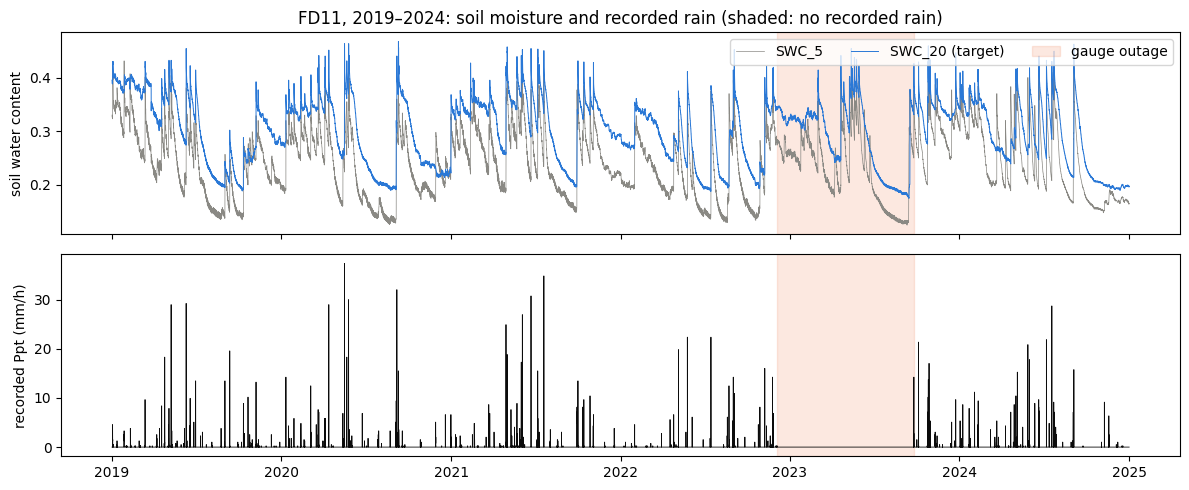

In [13]:
recorded_rain = station_df["Ppt"].clip(lower=0.0)
assert not recorded_rain.isna().any(), "Ppt has missing hours; the rain features below assume none"

# Longest runs of consecutive hours with no recorded rain
dry = recorded_rain == 0
run_id = (dry != dry.shift()).cumsum()
dry_runs = (station_df.index.to_series()[dry].groupby(run_id[dry]).agg(["min", "max", "size"])
            .sort_values("size", ascending=False).head(3))
print("Longest runs with no recorded rain:")
for start, end, size in dry_runs.itertuples(index=False):
    print(f"  {start} -> {end}: {size / 24:.0f} days")
outage_start, outage_end = dry_runs.iloc[0]["min"], dry_runs.iloc[0]["max"]

# Wetting events: SWC_5 rises more than 0.05 within 6 hours; a new event starts 24+ hours after the previous one
rising = station_df.index[(station_df["SWC_5"] - station_df["SWC_5"].rolling(6).min()) > 0.05]
event_starts = rising[np.r_[True, np.diff(rising) >= np.timedelta64(24, "h")]]
rain_near_event = recorded_rain.rolling(49, center=True, min_periods=1).sum().reindex(event_starts)  # +-24 hours
gauge_table = pd.DataFrame({
    "recorded_rain_mm": recorded_rain.groupby(recorded_rain.index.year).sum().round(0),
    "wetting_events": pd.Series(event_starts.year).value_counts(),
    "events_with_no_recorded_rain": pd.Series(event_starts.year[rain_near_event.to_numpy() < 1.0]).value_counts(),
}).fillna(0).astype(int)
gauge_table.index.name = "year"
gauge_table["use"] = ["train" if y in TRAIN_YEARS else "val" if y in VAL_YEARS else "test" if y in TEST_YEARS
                      else "SKIPPED" if y in SKIPPED_YEARS else "" for y in gauge_table.index]
print()
print(gauge_table.to_string())
assert not set(SKIPPED_YEARS) & set(MODEL_YEARS)

span = station_df.loc[f"{min(MODEL_YEARS)}-01-01":f"{max(MODEL_YEARS)}-12-31"]
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(span.index, span["SWC_5"], linewidth=0.5, color=C_MUTED, label="SWC_5")
axes[0].plot(span.index, span["SWC_20"], linewidth=0.7, color=C_MODEL, label="SWC_20 (target)")
axes[1].plot(span.index, span["Ppt"], linewidth=0.6, color=C_ACTUAL)
for ax in axes:
    ax.axvspan(outage_start, outage_end, color=C_LAST, alpha=0.15, label="gauge outage")
axes[0].set_ylabel("soil water content")
axes[0].legend(loc="upper right", ncol=3)
axes[1].set_ylabel("recorded Ppt (mm/h)")
axes[0].set_title(f"{STATION}, {min(MODEL_YEARS)}–{max(MODEL_YEARS)}: soil moisture and recorded rain "
                  f"(shaded: no recorded rain)")
plt.tight_layout()
plt.show()

**What this shows:** the 294-day run with no recorded rain (2022-12-04 → 2023-09-24) is more than six times longer
than any other dry spell in the record (the next is 46 days, January–February 2016). In 2023, 14 of 23 wetting
events have no recorded rain within ±24 hours, against at most 2 in any other year (0 in four of the five modeling
years, 1 in 2021). In the plot, `SWC_5` and `SWC_20` jump repeatedly inside the shaded outage while the rain trace
stays flat.

## 3. Feature engineering

Every feature at hour *t* is computed from data **at or before** *t* only (trailing windows and past shifts), on
the full `FD11` history, so the 30-day lookbacks are complete at 2019-01-01. All rainfall goes through the
1 mm/hour deadband first: hourly rain below `PPT_DEADBAND_MM` (fewer than four 0.254 mm tips) is set to zero,
because rain that light does not reach 20 cm.

**Soil state at 20 cm.** Persistence ignores where `SWC_20` is heading without new rain; these features describe it.

| Feature | Definition | Why |
|---|---|---|
| `SWC_20` | the target sensor | wetter soil drains faster; also needed to add the change back |
| `SWC_20_change_24h`, `SWC_20_change_72h` | `SWC_20(t) − SWC_20(t − 24 h / 72 h)` | the drydown rate, measured directly. Taken over whole days, so the sensor's daily temperature wiggle cancels; the 72h version reaches beyond the input window |
| `SWC_20_below_max_72h` | `SWC_20(t) −` its max over the last 72 h (≤ 0) | where the soil is in the recession after a wetting peak: right after a peak it drains fast |
| `SWC_20_above_min_30d` | `SWC_20(t) −` its min over the last 30 days (≥ 0) | water above the recent dry floor, i.e. how much can still drain |

**The 5 cm sensor.** A wetting front reaches `SWC_5` first, so whether it rose shows if the rain in the window
actually infiltrated or stayed near the surface (light summer rain on dry soil). The LSTM reads its short-term
change and its gap to `SWC_20` from the 24-hour sequence itself.

**Rain memory.** Rain from before the 24-hour window still controls the next 72 hours.

| Feature | Definition |
|---|---|
| `Ppt_rolling_24h_log`, `Ppt_rolling_72h_log`, `Ppt_rolling_168h_log` | `log1p` of the deadbanded rain total over the last 1, 3 and 7 days (current hour included) |
| `hours_since_rain_log` | `log1p` of the hours since the last hour with rain, capped at 30 days |
| `api_log` | `log1p` of the antecedent precipitation index, `api[t] = 0.98 · api[t−1] + rain[t]` (half-life about 34 hours) |

**Left out, on purpose:**

- **Soil temperature (`T_5/10/20`), day of year, season.** With three training years, a seasonal feature partly
  identifies the year rather than the drydown, which the change features already measure directly. In a quick
  check (gradient boosting on these features at the window's last hour), adding any of them made the validation
  and test MAE worse.
- **Hour of day.** 72 hours is a whole number of days, so the target hour has the same time of day as the window's
  last hour, and persistence already cancels the daily cycle.
- **`Tair`, `RH`, `Srad`, wind.** These are 100% synthetic (`modeling_completion`) at `FD11`.
- **`SWC_10`.** At `FD11` it is stored about 100× too small and rounded to three decimals, so it takes only four
  values (0.001–0.004, Section 1). Every 0.001 step is a quarter of its range and would look like a sudden wetting
  jump to the network. In the same quick check, dropping it left the scores unchanged or slightly better.
- **`SWC_50`, `T_50`.** These sit below the 20 cm target, so they are downstream of it.

In [14]:
def deadband(ppt, threshold=PPT_DEADBAND_MM):
    """Hourly rainfall below `threshold` mm set to 0 (too light to reach 20 cm)."""
    return ppt.mask(ppt < threshold, 0.0)


def hours_since_rain(rain, cap=HOURS_SINCE_RAIN_CAP):
    """Hours since the last hour with rain (0 in a rainy hour), capped at `cap`; `cap` before the first rain."""
    last_rain = pd.Series(rain.index.where(rain.to_numpy() > 0), index=rain.index).ffill()
    hours = (rain.index.to_series() - last_rain).dt.total_seconds() / 3600
    return hours.fillna(cap).clip(upper=cap)


def antecedent_precipitation_index(rain, decay=API_DECAY_PER_HOUR):
    """api[t] = decay * api[t-1] + rain[t]: the latest rain counts fully, older rain fades out."""
    api = np.zeros(len(rain))
    level = 0.0
    for i, r in enumerate(rain.to_numpy()):
        level = decay * level + r
        api[i] = level
    return pd.Series(api, index=rain.index)


def engineer_features(hist, rain):
    """Every candidate model input, on the full hourly history. A feature at hour t uses data at or before t only.
    hist: the station history (complete hourly grid); rain: its deadbanded hourly rainfall."""
    swc = hist["SWC_20"]
    f = pd.DataFrame(index=hist.index)
    # soil state at 20 cm
    f["SWC_20"] = swc
    f["SWC_20_change_24h"] = swc - swc.shift(24)
    f["SWC_20_change_72h"] = swc - swc.shift(72)
    f["SWC_20_below_max_72h"] = swc - swc.rolling(72, min_periods=72).max()
    f["SWC_20_above_min_30d"] = swc - swc.rolling(720, min_periods=720).min()
    # shallower sensors
    f["SWC_5"] = hist["SWC_5"]
    f["SWC_10"] = hist["SWC_10"]
    # rain memory
    for hours in (24, 72, 168):
        f[f"Ppt_rolling_{hours}h_log"] = np.log1p(rain.rolling(hours, min_periods=hours).sum())
    f["hours_since_rain_log"] = np.log1p(hours_since_rain(rain))
    f["api_log"] = np.log1p(antecedent_precipitation_index(rain))
    return f


rain = deadband(recorded_rain)
rainy = model_rows["Ppt"] > 0
zeroed = rainy & (model_rows["Ppt"] < PPT_DEADBAND_MM)
print(f"Deadband (< {PPT_DEADBAND_MM:g} mm/h), modeling years: zeroes {zeroed.sum() / rainy.sum():.1%} of rainy "
      f"hours, {model_rows.loc[zeroed, 'Ppt'].sum() / model_rows['Ppt'].sum():.1%} of the rain volume")

features = engineer_features(station_df, rain)
missing = set(FEATURES) - set(features.columns)
assert not missing, f"features not built: {missing}"
assert TARGET_COL in BASE_FEATURES and set(BASE_FEATURES) <= set(FEATURES)

df = features.loc[features.index.year.isin(MODEL_YEARS), FEATURES].copy()
df[f"{TARGET_COL}_Origin"] = station_df.loc[df.index, f"{TARGET_COL}_Origin"]
assert not df[FEATURES].isna().any().any(), "a model input contains NaN"

# Evaluation only, never an input: deadbanded rain in the HORIZON hours after each hour, i.e. in the gap between a
# window's last hour and its target. Section 13.2 uses it to split the scores into forecastable and not.
GAP_RAIN = rain[::-1].rolling(HORIZON, min_periods=HORIZON).sum()[::-1].shift(-1)

print(f"{len(FEATURES)} features, {len(df)} rows. Training-year summary:")
display(df.loc[df.index.year.isin(TRAIN_YEARS), FEATURES].describe().T[["mean", "std", "min", "max"]].round(4))

Deadband (< 1 mm/h), modeling years: zeroes 59.2% of rainy hours, 10.6% of the rain volume
11 features, 43848 rows. Training-year summary:


,mean,std,min,max
SWC_20,0.3090,0.0635,0.189,0.4670
SWC_20_change_24h,-0.0001,0.0169,-0.074,0.2040
SWC_20_change_72h,-0.0003,0.0272,-0.092,0.2460
SWC_20_below_max_72h,-0.0139,0.0143,-0.092,0.0000
SWC_20_above_min_30d,0.0396,0.0501,0.000,0.2770
SWC_5,0.2436,0.0609,0.126,0.4310
Ppt_rolling_24h_log,0.2581,0.7552,0.000,4.2641
Ppt_rolling_72h_log,0.6675,1.1589,0.000,4.7095
Ppt_rolling_168h_log,1.3395,1.4336,0.000,4.8948
hours_since_rain_log,4.7004,1.3297,0.000,6.5806


## 4. Feature check (training years only)

First, two numbers that frame the problem. Then each feature's rank (Spearman) correlation with what the network
predicts, the 72-hour **change** in `SWC_20` rather than its level, over the training years only. It is shown for
all hours and for hours with no rain in the following 72 hours (the forecastable part). Spearman, because the
change has a long tail of rain jumps that would dominate a Pearson correlation.

In [15]:
train_rows = df[df.index.year.isin(TRAIN_YEARS)]
change = train_rows[TARGET_COL].shift(-HORIZON) - train_rows[TARGET_COL]   # NaN where the target leaves 2019-2021
ok = change.notna()
no_gap_rain = ok & (GAP_RAIN.reindex(train_rows.index) < GAP_RAIN_MM)
sq_err = change[ok] ** 2                                                    # persistence predicts no change
print(f"Training years: {(ok & ~no_gap_rain).sum() / ok.sum():.0%} of hours have >= {GAP_RAIN_MM:g} mm of rain in "
      f"the next {HORIZON} h; they carry {sq_err[~no_gap_rain[ok]].sum() / sq_err.sum():.0%} of persistence's "
      f"squared error.")
print(f"{HORIZON}h change in SWC_20: median {change[ok].median():+.4f}, mean {change[ok].mean():+.4f} (all hours); "
      f"median {change[no_gap_rain].median():+.4f} with no gap rain (persistence predicts 0).")

feature_check = pd.DataFrame({
    "spearman_r_all_hours": {c: train_rows.loc[ok, c].corr(change[ok], method="spearman") for c in FEATURES},
    "spearman_r_no_gap_rain": {c: train_rows.loc[no_gap_rain, c].corr(change[no_gap_rain], method="spearman")
                               for c in FEATURES},
    "group": {c: g for g, cols in FEATURE_GROUPS.items() for c in cols},
})
feature_check.index.name = f"vs {HORIZON}h change"
display(feature_check.round(3))

Training years: 25% of hours have >= 2 mm of rain in the next 72 h; they carry 83% of persistence's squared error.
72h change in SWC_20: median -0.0050, mean -0.0003 (all hours); median -0.0060 with no gap rain (persistence predicts 0).


,spearman_r_all_hours,spearman_r_no_gap_rain,group
vs 72h change,,,
SWC_20,-0.323,-0.438,soil state at 20 cm
SWC_20_change_24h,0.227,0.332,soil state at 20 cm
SWC_20_change_72h,0.092,0.144,soil state at 20 cm
SWC_20_below_max_72h,0.372,0.495,soil state at 20 cm
SWC_20_above_min_30d,-0.204,-0.341,soil state at 20 cm
SWC_5,-0.223,-0.328,5 cm sensor
Ppt_rolling_24h_log,-0.136,-0.186,rain memory
Ppt_rolling_72h_log,-0.157,-0.234,rain memory
Ppt_rolling_168h_log,-0.199,-0.299,rain memory


**What this shows:** a quarter of the training hours have at least 2 mm of rain in the next 72 hours, and they
carry 83% of persistence's squared error. Without gap rain, `SWC_20` falls by a median 0.006 over 72 hours, which
persistence misses every time. Over all hours the mean change (−0.0003) sits well above the median (−0.005); that
gap is the bias an MSE loss builds in.

Every feature correlates more strongly with the change when there is no gap rain, the forecastable part:

- **Strongest:** where the soil sits relative to its recent peak (`SWC_20_below_max_72h`, 0.50) and its level
  (`SWC_20`, −0.44: wetter soil drains faster).
- **Next:** the antecedent precipitation index, the height above the 30-day minimum, the 24h trend and `SWC_5`
  (|r| 0.33–0.35).
- **Weakest:** the 72h change (0.14); it mainly adds context from before the window.

## 5. Year split: train 2019–2021, validation 2022, test 2024

Whole calendar years, chronological, so every season appears in each partition.

- **Train, 2019–2021 (3 years).** Fits the model. The CV check (Section 11) runs inside this block only.
- **Validation, 2022.** Used only for early stopping of the final model.
- **Test, 2024.** Touched once, at the very end.

2023 sits between validation and test and is not used. Windows are built separately inside each partition, so no
window crosses a partition boundary or the skipped year.

In [16]:
def rows_in_years(data_df, years):
    """Rows of data_df whose timestamp falls in one of the calendar `years`."""
    return data_df[data_df.index.year.isin(years)]


def year_span(years):
    """'2019-2021' for a run of years, '2022' for a single year."""
    return f"{years[0]}-{years[-1]}" if len(years) > 1 else str(years[0])


def assert_whole_years(part, years):
    """part must be exactly the consecutive calendar `years`, every hour present."""
    assert list(years) == list(range(years[0], years[-1] + 1)), f"{years} are not consecutive years"
    full = pd.date_range(f"{years[0]}-01-01", f"{years[-1] + 1}-01-01", freq="h", inclusive="left")
    assert len(part) == len(full) and (part.index == full).all(), f"{year_span(years)} is not complete hourly years"


train_df = rows_in_years(df, TRAIN_YEARS)
val_df = rows_in_years(df, VAL_YEARS)
test_df = rows_in_years(df, TEST_YEARS)
for name, part, years in [("train", train_df, TRAIN_YEARS), ("val", val_df, VAL_YEARS), ("test", test_df, TEST_YEARS)]:
    assert_whole_years(part, years)
    print(f"{name:5s}: {year_span(years):9s} {len(part):6d} rows  {part.index.min()} -> {part.index.max()}")
assert train_df.index.max() < val_df.index.min() <= val_df.index.max() < test_df.index.min()
assert len(train_df) + len(val_df) + len(test_df) == len(df)

train: 2019-2021  26304 rows  2019-01-01 00:00:00 -> 2021-12-31 23:00:00
val  : 2022        8760 rows  2022-01-01 00:00:00 -> 2022-12-31 23:00:00
test : 2024        8784 rows  2024-01-01 00:00:00 -> 2024-12-31 23:00:00


## 6. Normalization

`MinMaxScaler`, fit on the training years only and reused (never refit) for validation and test. Validation and
test values can fall outside `[0, 1]`. Each CV fold fits its own scaler on its own training years (Section 11).

In [17]:
scaler = MinMaxScaler().fit(train_df[FEATURES])   # fit on TRAIN ONLY


def scale(split_df, cols=FEATURES, fitted_scaler=scaler):
    arr = fitted_scaler.transform(split_df[cols]).astype(np.float32)
    return pd.DataFrame(arr, columns=cols, index=split_df.index)


def unscale_target(values, fitted_scaler=scaler):
    """Scaled SWC_20 values back to original SWC_20 units."""
    pos = list(fitted_scaler.feature_names_in_).index(TARGET_COL)
    lo, hi = fitted_scaler.data_min_[pos], fitted_scaler.data_max_[pos]
    return np.asarray(values, dtype=np.float64) * (hi - lo) + lo


train_scaled = scale(train_df)
assert np.allclose(train_scaled.min(), 0) and np.allclose(train_scaled.max(), 1)   # train is exactly [0, 1]

## 7. Building X/Y windows

A 24-hour window slides across each partition. Inputs are rows `[start, end − 1]`, and the target is `SWC_20` at
row `end − 1 + HORIZON`, 72 hours after the window's last hour. Windows whose target hour is not an `observed`
`SWC_20` reading are dropped after windowing, never the source rows.

**Change target.** `y = SWC_20(target hour) − SWC_20(last input hour)`, in scaled units. An output of 0 *is*
persistence, so everything the network learns goes into what persistence misses. `to_level` adds the predicted
change back to the last value and unscales it, so every score is in `SWC_20` units.

In [18]:
def make_windows(data_df, feature_cols, target_col, window_size, horizon):
    """
    data_df: chronologically ordered dataframe (scaled for the model, unscaled for the baselines).
    window_size: number of past hours used as input (X).
    horizon: how many hours AFTER the window's last hour the target sits.

    Returns X (num_samples, window_size, num_features), y (num_samples,), and the row-index
    (within data_df) of each window's last input hour / its target hour, for verification.
    """
    values = data_df[feature_cols].values
    targets = data_df[target_col].values
    n = len(data_df)

    X, y, end_idx, target_idx = [], [], [], []
    for start in range(0, n - window_size - horizon + 1):
        end = start + window_size          # first index AFTER the window (exclusive)
        tgt = end - 1 + horizon            # horizon hours after the window's LAST hour (end - 1)
        X.append(values[start:end])
        y.append(targets[tgt])
        end_idx.append(end - 1)
        target_idx.append(tgt)

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), end_idx, target_idx


def check_window_alignment(index, end_idx, target_idx, window_size, horizon):
    """Asserts every input covers `window_size` consecutive hourly steps and every target is exactly `horizon`
    hours after its window's last input hour, all inside the partition that `index` belongs to."""
    index = pd.DatetimeIndex(index)
    end_idx, target_idx = np.asarray(end_idx), np.asarray(target_idx)
    assert len(target_idx) > 0, "partition too short for one window"
    assert (np.diff(index.values) == np.timedelta64(1, "h")).all(), "partition is not consecutive hourly data"
    start_idx = end_idx - (window_size - 1)
    assert start_idx.min() >= 0 and target_idx.max() < len(index)       # nothing outside this partition
    assert ((index[end_idx] - index[start_idx]) == pd.Timedelta(hours=window_size - 1)).all()
    assert ((index[target_idx] - index[end_idx]) == pd.Timedelta(hours=horizon)).all()


def observed_target_mask(split_df, target_idx):
    """True for windows whose target hour has an observed SWC_20 reading (split_df carries SWC_20_Origin)."""
    origin = split_df[f"{TARGET_COL}_Origin"].to_numpy()
    return origin[np.asarray(target_idx, dtype=int)] == "observed"


def last_scaled_target(X, feature_cols):
    """Scaled SWC_20 at each window's last input hour (SWC_20 is always an input)."""
    return X[:, -1, list(feature_cols).index(TARGET_COL)]


def observed_windows(split_df, split_scaled, feature_cols):
    """Windows of one partition whose target is an observed SWC_20 reading: X, y, end_idx, target_idx.
    y is the scaled change in SWC_20 from the window's last hour to the target hour."""
    X, y, end_idx, target_idx = make_windows(split_scaled, feature_cols, TARGET_COL, WINDOW_SIZE, HORIZON)
    keep = observed_target_mask(split_df, target_idx)
    X = X[keep]
    y = y[keep] - last_scaled_target(X, feature_cols)
    return X, y, np.asarray(end_idx)[keep], np.asarray(target_idx)[keep]


def to_level(X, pred, feature_cols, fitted_scaler):
    """Predicted scaled changes for windows X -> SWC_20 in original units (added back to each last value)."""
    return unscale_target(pred + last_scaled_target(X, feature_cols), fitted_scaler)

In [19]:
# Worked example with real timestamps: first, middle and last training window. The target, converted back, must
# equal the SWC_20 value looked up by the target's TIMESTAMP (independent of the index arithmetic).
X_demo, y_demo, end_idx_demo, target_idx_demo = make_windows(train_scaled, FEATURES, TARGET_COL, WINDOW_SIZE, HORIZON)
for i in (0, len(y_demo) // 2, len(y_demo) - 1):
    t_start = train_df.index[end_idx_demo[i] - (WINDOW_SIZE - 1)]
    t_end, t_tgt = train_df.index[end_idx_demo[i]], train_df.index[target_idx_demo[i]]
    y_orig = unscale_target(y_demo[i])
    print(f"window {i:5d}: inputs {t_start} -> {t_end} | target {t_tgt} "
          f"(+{(t_tgt - t_end) / pd.Timedelta(hours=1):.0f}h) | y = {y_orig:.4f}, "
          f"SWC_20 at {t_tgt} = {df.loc[t_tgt, TARGET_COL]:.4f}")
    assert t_tgt - t_end == pd.Timedelta(hours=HORIZON)
    assert abs(y_orig - df.loc[t_tgt, TARGET_COL]) < 1e-6
print(f"X dims: {X_demo.shape} = (num_samples, window_size, num_features);  y dims: {y_demo.shape}")

# The change target round-trips: to_level(X, y) gives back the observed SWC_20 at every target hour
X_obs, y_obs, _, target_idx_obs = observed_windows(train_df, train_scaled, FEATURES)
assert np.allclose(to_level(X_obs, y_obs, FEATURES, scaler), train_df[TARGET_COL].to_numpy()[target_idx_obs], atol=1e-5)

# Every window of every partition: 24 consecutive hourly inputs, target exactly HORIZON hours after the last input
exclusions = {}
for part_name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    _, _, end_idx, target_idx = make_windows(part, [TARGET_COL], TARGET_COL, WINDOW_SIZE, HORIZON)
    check_window_alignment(part.index, end_idx, target_idx, WINDOW_SIZE, HORIZON)
    keep = observed_target_mask(part, target_idx)
    exclusions[part_name] = {"windows": len(keep), "observed_targets": int(keep.sum()),
                             "non_observed_targets_dropped": int((~keep).sum())}
print(f"Window alignment checks passed for the {HORIZON}h horizon in train, val and test.")
pd.DataFrame(exclusions).T

window     0: inputs 2019-01-01 00:00:00 -> 2019-01-01 23:00:00 | target 2019-01-04 23:00:00 (+72h) | y = 0.4050, SWC_20 at 2019-01-04 23:00:00 = 0.4050
window 13104: inputs 2020-06-30 00:00:00 -> 2020-06-30 23:00:00 | target 2020-07-03 23:00:00 (+72h) | y = 0.2400, SWC_20 at 2020-07-03 23:00:00 = 0.2400
window 26208: inputs 2021-12-28 00:00:00 -> 2021-12-28 23:00:00 | target 2021-12-31 23:00:00 (+72h) | y = 0.2940, SWC_20 at 2021-12-31 23:00:00 = 0.2940
X dims: (26209, 24, 11) = (num_samples, window_size, num_features);  y dims: (26209,)
Window alignment checks passed for the 72h horizon in train, val and test.


,windows,observed_targets,non_observed_targets_dropped
train,26209,26207,2
val,8665,8665,0
test,8689,8689,0


## 8. The model: a unidirectional LSTM

```
input    (batch, 24 hours, 11 features)
nn.LSTM(input_size=11, hidden_size=32, num_layers=1, batch_first=True)
           reads hour 1 -> hour 24 -> h_n[-1], the final hidden state      (batch, 32)
Linear(32 -> 1)
output   (batch, 1)   <- scaled change in SWC_20 from the window's last hour to 72 hours later
```

A unidirectional LSTM is the standard choice for forecasting. The gates carry things like "it rained 30 hours ago"
or "the soil has been drying steadily" forward through the window. The configuration is fixed and small (one layer,
hidden size 32): with three training years, a bigger network mostly has more room to fit noise. Zero initial
states; structure after the GeeksforGeeks PyTorch LSTM tutorial,
[Long Short-Term Memory Networks using PyTorch](https://www.geeksforgeeks.org/deep-learning/long-short-term-memory-networks-using-pytorch/).

In [20]:
class SimpleLSTM(nn.Module):
    def __init__(self, num_features, hidden_size, num_layers):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=num_features,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x: (batch, 24, num_features)
        _, (h_n, _) = self.lstm(x)          # h_n: (num_layers, batch, hidden_size); h0/c0 default to zeros
        return self.fc(h_n[-1])             # last layer, after reading hour 1 -> 24  -> (batch, 1)


def build_model(config, num_features):
    return SimpleLSTM(num_features, hidden_size=config["hidden_size"], num_layers=config["num_layers"])


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


m = build_model(MODEL_CONFIG, len(FEATURES))
assert m(torch.zeros(5, WINDOW_SIZE, len(FEATURES))).shape == (5, 1)
print(f"LSTM ({MODEL_CONFIG['num_layers']} layer, hidden {MODEL_CONFIG['hidden_size']}, {len(FEATURES)} inputs): "
      f"{count_parameters(m):,} parameters")

LSTM (1 layer, hidden 32, 11 inputs): 5,793 parameters


## 9. Metrics, loss and training

**Metrics.** MSE, RMSE, MAE, MAPE, SMAPE, RSE and CORR as in the earlier notebooks, plus **Bias**, the mean of
`prediction − actual`. Bias is positive when the model forecasts too wet.

**Loss: Huber, δ = 0.005 `SWC_20`.** The loss is quadratic for errors below δ and linear above it. δ is about the
size of a typical 72-hour drydown, and it is converted to scaled units with the scaler's `SWC_20` range. Rain that
falls in the gap makes errors of 0.03–0.15. Those land in the linear part, so they pull on the forecast with a fixed
force instead of one proportional to their size, and the forecast settles near the typical (median-like) outcome
rather than the mean. Small errors stay quadratic, so training is smooth near the optimum, where plain L1 would keep
a constant gradient. Early stopping uses the same loss on the validation windows.

**Training.** A plain manual loop: Adam, up to 30 epochs, early stopping with patience 10, and the best validation
epoch's weights restored. Training batches (size 16) are sliced from tensors that already live on the device.

In [21]:
def compute_metrics(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=np.float64).flatten()
    y_pred = np.asarray(y_pred, dtype=np.float64).flatten()

    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + eps))) * 100
    smape = np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps)) * 100
    rse = np.sum((y_pred - y_true) ** 2) / (np.sum((y_true - y_true.mean()) ** 2) + eps)
    corr = np.corrcoef(y_true, y_pred)[0, 1] if min(np.std(y_true), np.std(y_pred)) > 1e-12 else float("nan")
    bias = np.mean(y_pred - y_true)

    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "MAPE": mape, "SMAPE": smape, "RSE": rse, "CORR": corr,
            "Bias": bias}


METRIC_COLS = ["MSE", "RMSE", "MAE", "MAPE", "SMAPE", "RSE", "CORR", "Bias"]

# Sanity checks against known cases
perfect = compute_metrics([1, 2, 3], [1, 2, 3])
assert perfect["MSE"] == 0 and perfect["MAE"] == 0 and abs(perfect["CORR"] - 1.0) < 1e-9
assert abs(compute_metrics([0.0, 0.0], [3.0, 4.0])["RMSE"] - np.sqrt(12.5)) < 1e-12
assert compute_metrics([1.0, 1.0], [1.5, 2.5])["Bias"] == 1.0


def make_criterion(loss, fitted_scaler):
    """Training loss on the scaled change. HUBER_DELTA is in SWC_20 units and is converted with the scaler's SWC_20
    range, so the threshold means the same thing in every fold."""
    if loss == "mse":
        return nn.MSELoss()
    if loss == "huber":
        pos = list(fitted_scaler.feature_names_in_).index(TARGET_COL)
        return nn.HuberLoss(delta=HUBER_DELTA / (fitted_scaler.data_max_[pos] - fitted_scaler.data_min_[pos]))
    raise ValueError(f"unknown loss {loss!r}")


# Huber: quadratic below delta, linear above (an error of 3 with delta 1 costs 1 * (3 - 0.5) = 2.5, not 4.5)
assert nn.HuberLoss(delta=1.0)(torch.tensor([3.0]), torch.tensor([0.0])).item() == 2.5
print(f"Huber delta: {HUBER_DELTA} SWC_20 = {make_criterion('huber', scaler).delta:.4f} in scaled units")

Huber delta: 0.005 SWC_20 = 0.0180 in scaled units


In [22]:
def train_model(model, train_loader, val_loader, criterion, epochs=EPOCHS, patience=PATIENCE, lr=1e-3):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses, val_losses = [], []
    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(epochs):
        model.train()                          # training mode
        running_loss = 0.0
        for xb, yb in train_loader:            # batches already live on DEVICE
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.detach() * xb.size(0)   # summed on the device: no CPU-GPU sync every step
        train_loss = running_loss.item() / len(train_loader.dataset)
        train_losses.append(train_loss)

        model.eval()                           # evaluation mode
        val_running = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                pred = model(xb)
                val_running += criterion(pred, yb).item() * xb.size(0)
        val_loss = val_running / len(val_loader.dataset)
        val_losses.append(val_loss)

        if val_loss < best_val_loss - 1e-7:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)      # restore the best-validation epoch

    return model, train_losses, val_losses, best_epoch


class DeviceLoader:
    """(X, y) batches sliced from tensors that live on DEVICE. The sample order comes from an index-only
    DataLoader with the same generator, so the batches are exactly those of DataLoader(TensorDataset(X, y), ...)
    -- without collating every sample on the CPU and copying each batch to the GPU."""
    def __init__(self, X, y, batch_size, shuffle=False, generator=None):
        self.X = torch.as_tensor(X, device=DEVICE)
        self.y = torch.as_tensor(y, device=DEVICE).unsqueeze(1)
        self.dataset = self.y                  # len(loader.dataset) = number of samples, as for a DataLoader
        self.batch_size = batch_size
        self.index_loader = DataLoader(torch.arange(len(self.y)), batch_size=batch_size, shuffle=shuffle,
                                       generator=generator)

    def __iter__(self):
        order = torch.cat(list(self.index_loader)).to(DEVICE)   # this epoch's sample order, one copy to DEVICE
        for start in range(0, len(order), self.batch_size):
            idx = order[start:start + self.batch_size]
            yield self.X[idx], self.y[idx]


def make_loaders(X_train, y_train, X_val, y_val, batch_size, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    return (DeviceLoader(X_train, y_train, batch_size, shuffle=True, generator=g),
            DeviceLoader(X_val, y_val, EVAL_BATCH_SIZE))


def predict(model, X, batch_size=EVAL_BATCH_SIZE):
    """Raw network outputs (scaled changes) for X, in order."""
    model.eval()
    with torch.no_grad():
        return torch.cat([model(torch.tensor(X[i:i + batch_size]).to(DEVICE)).cpu()
                          for i in range(0, len(X), batch_size)]).numpy().flatten()


def fit(feature_cols, loss, fit_df, stop_df, fitted_scaler, config=MODEL_CONFIG, seed=SEED):
    """Trains one LSTM on fit_df's observed-target windows, early-stopped on stop_df's. Returns the restored
    best-epoch model, per-epoch training and validation losses, and the best epoch."""
    cols = list(feature_cols)
    Xtr, ytr, _, _ = observed_windows(fit_df, scale(fit_df, cols, fitted_scaler), cols)
    Xv, yv, _, _ = observed_windows(stop_df, scale(stop_df, cols, fitted_scaler), cols)
    train_loader, val_loader = make_loaders(Xtr, ytr, Xv, yv, config["batch_size"], seed)
    torch.manual_seed(seed)
    model = build_model(config, len(cols))
    return train_model(model, train_loader, val_loader, make_criterion(loss, fitted_scaler), lr=config["lr"])


def predict_windows(model, part_df, feature_cols, fitted_scaler):
    """Predictions for every observed-target window of one partition, in original SWC_20 units."""
    cols = list(feature_cols)
    X, _, end_idx, target_idx = observed_windows(part_df, scale(part_df, cols, fitted_scaler), cols)
    return {"y_true": part_df[TARGET_COL].to_numpy()[target_idx],      # observed values, unscaled
            "y_pred": to_level(X, predict(model, X), cols, fitted_scaler),
            "end_time": part_df.index[end_idx], "target_time": part_df.index[target_idx]}

## 10. Naive baselines: last value and moving average

Two models with nothing to learn, scored on **exactly the same targets** as the LSTM (same windows, same horizon,
same observed-target filter), from the unscaled partitions:

- **Last value (persistence):** `SWC_20` at the target time equals `SWC_20` at the window's last hour.
- **Moving average (24h):** the mean `SWC_20` over the 24-hour input window.

In [23]:
def naive_baselines(data_df, ma_window=WINDOW_SIZE):
    """True targets and naive predictions for every window with an observed target, in original SWC_20 units."""
    X, y, _, target_idx = make_windows(data_df, [TARGET_COL], TARGET_COL, WINDOW_SIZE, HORIZON)
    keep = observed_target_mask(data_df, target_idx)   # same targets as the LSTM
    swc = X[keep, :, 0]
    return y[keep], {
        "Last value": swc[:, -1],
        f"Moving average ({ma_window}h)": swc[:, -ma_window:].mean(axis=1),
    }


naive = {name: naive_baselines(part) for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]}
NAIVE_NAMES = list(naive["test"][1])

## 11. Time-series cross-validation check

`TimeSeriesSplit(n_splits=2)` is applied to the training **years** themselves, so every fold trains and validates
on whole seasonal cycles:

| fold | train | validate |
|---|---|---|
| 1 | 2019 | 2020 |
| 2 | 2019–2020 | 2021 |

Nothing is tuned here. The CV tests the two design choices on years the final model is neither early-stopped nor
tested on: the 2 earlier inputs vs the 11 engineered features, and MSE vs Huber. That is four variants × two
folds = 8 fits. Each fit gets its own scaler fit on the fold's training years, up to 30 epochs and patience 10, the
same as the final model. Each fold's validation year both early-stops and scores its fit, so the CV scores are
slightly optimistic, equally for every variant; the final model is scored on 2024, which nothing else touches.

`RMSE_skill` / `MAE_skill` = 1 − model / last value on the same windows; positive means the model beats
persistence. A variant is convincing only if it beats last value on **both** folds, on RMSE **and** MAE.

In [24]:
years = np.array(TRAIN_YEARS)
CV_FOLD_YEARS = [(years[tr].tolist(), years[va].tolist())
                 for tr, va in TimeSeriesSplit(n_splits=N_CV_SPLITS).split(years)]
cv_folds, cv_last_value = [], []
for k, (fold_train_years, fold_val_years) in enumerate(CV_FOLD_YEARS, start=1):
    assert max(fold_train_years) < min(fold_val_years), "always train on the past, validate on the future"
    tr, va = rows_in_years(train_df, fold_train_years), rows_in_years(train_df, fold_val_years)
    y_true, naive_preds = naive_baselines(va)   # persistence on exactly this fold's scored windows
    cv_last_value.append(compute_metrics(y_true, naive_preds["Last value"]))
    cv_folds.append((tr, va))
    print(f"fold {k}: train {year_span(fold_train_years)} ({len(tr)} rows) | validate {year_span(fold_val_years)} "
          f"({len(y_true)} scored windows) | last value RMSE {cv_last_value[-1]['RMSE']:.5f}, "
          f"MAE {cv_last_value[-1]['MAE']:.5f}")

CV_VARIANTS = {
    f"{len(BASE_FEATURES)} earlier inputs, MSE": (BASE_FEATURES, "mse"),
    f"{len(BASE_FEATURES)} earlier inputs, Huber": (BASE_FEATURES, "huber"),
    f"{len(FEATURES)} engineered, MSE": (FEATURES, "mse"),
    f"{len(FEATURES)} engineered, Huber": (FEATURES, "huber"),
}
FINAL_VARIANT = f"{len(FEATURES)} engineered, Huber"   # what the final model uses
assert CV_VARIANTS[FINAL_VARIANT] == (FEATURES, LOSS)

fold 1: train 2019 (8760 rows) | validate 2020 (8689 scored windows) | last value RMSE 0.02668, MAE 0.01355
fold 2: train 2019-2020 (17544 rows) | validate 2021 (8665 scored windows) | last value RMSE 0.03042, MAE 0.01718


In [25]:
def fit_fold(feature_cols, loss, k):
    """One CV fit on fold k: scaler and model fit on the fold's training years, early-stopped and scored on its
    validation year. Returns the validation metrics in SWC_20 units, best epoch, epochs run and seconds."""
    t0 = time.time()
    if N_JOBS > 1:
        torch.set_num_threads(1)       # one thread per worker process; at batch size 16 more threads do not help
    fold_train, fold_val = cv_folds[k]
    fold_scaler = MinMaxScaler().fit(fold_train[feature_cols])   # this fold's training years only
    model, train_losses, _, best_epoch = fit(feature_cols, loss, fold_train, fold_val, fold_scaler)
    p = predict_windows(model, fold_val, feature_cols, fold_scaler)
    return {**compute_metrics(p["y_true"], p["y_pred"]), "best_epoch": best_epoch,
            "epochs_run": len(train_losses), "seconds": time.time() - t0}


print(f"CV check: {len(CV_VARIANTS)} variants x {len(cv_folds)} folds, up to {EPOCHS} epochs (patience {PATIENCE}), "
      f"N_JOBS={N_JOBS} ...")
t_cv = time.time()
jobs = [(name, k) for name in CV_VARIANTS for k in range(len(cv_folds))]
# max_nbytes=None: send the (small) fold data to CPU workers as ordinary writable copies, not read-only memmaps
fits = Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(fit_fold)(*CV_VARIANTS[name], k) for name, k in jobs)
cv_results = dict(zip(jobs, fits))
print(f"  {(time.time() - t_cv) / 60:.1f} min")

rows = {}
for name in CV_VARIANTS:
    row = {}
    for k, last in enumerate(cv_last_value):
        r = cv_results[(name, k)]
        row.update({f"fold{k + 1}_RMSE": r["RMSE"], f"fold{k + 1}_RMSE_skill": 1 - r["RMSE"] / last["RMSE"],
                    f"fold{k + 1}_MAE": r["MAE"], f"fold{k + 1}_MAE_skill": 1 - r["MAE"] / last["MAE"],
                    f"fold{k + 1}_Bias": r["Bias"], f"fold{k + 1}_best_epoch": r["best_epoch"],
                    f"fold{k + 1}_epochs_run": r["epochs_run"]})
    skills = [row[f"fold{k + 1}_{m}_skill"] for k in range(len(cv_folds)) for m in ("RMSE", "MAE")]
    row["mean_RMSE_skill"] = np.mean([row[f"fold{k + 1}_RMSE_skill"] for k in range(len(cv_folds))])
    row["mean_MAE_skill"] = np.mean([row[f"fold{k + 1}_MAE_skill"] for k in range(len(cv_folds))])
    row["beats_last_value_everywhere"] = bool(min(skills) > 0)
    rows[name] = row
rows["Last value"] = {**{f"fold{k + 1}_{m}": last[m] for k, last in enumerate(cv_last_value)
                         for m in ("RMSE", "MAE", "Bias")}}
cv_table = pd.DataFrame.from_dict(rows, orient="index")
cv_table.index.name = "variant"
cv_table.to_csv(output_path("cv_check.csv"))

summary_cols = (["mean_RMSE_skill", "mean_MAE_skill", "beats_last_value_everywhere"]
                + [f"fold{k + 1}_{m}" for k in range(len(cv_folds)) for m in ("RMSE_skill", "MAE_skill", "Bias")])
display(cv_table.loc[list(CV_VARIANTS), summary_cols].style
        .format("{:+.1%}", subset=[c for c in summary_cols if "skill" in c])
        .format("{:+.5f}", subset=[c for c in summary_cols if c.endswith("Bias")]))
display(cv_table[[c for c in cv_table.columns if "skill" not in c and c != "beats_last_value_everywhere"]]
        .style.format("{:.5f}", na_rep="", subset=[c for c in cv_table.columns if c.endswith(("RMSE", "MAE", "Bias"))])
        .format("{:.0f}", na_rep="", subset=[c for c in cv_table.columns if c.endswith(("epoch", "run"))]))
best = cv_table.loc[list(CV_VARIANTS), "mean_MAE_skill"].idxmax()
print(f"Final variant '{FINAL_VARIANT}': beats last value on every fold and metric: "
      f"{cv_table.loc[FINAL_VARIANT, 'beats_last_value_everywhere']}; highest mean MAE skill: '{best}'")

CV check: 4 variants x 2 folds, up to 30 epochs (patience 10), N_JOBS=1 ...
  4.4 min


,mean_RMSE_skill,mean_MAE_skill,beats_last_value_everywhere,fold1_RMSE_skill,fold1_MAE_skill,fold1_Bias,fold2_RMSE_skill,fold2_MAE_skill,fold2_Bias
variant,,,,,,,,,
"2 earlier inputs, MSE",+4.6%,+7.9%,True,+3.7%,+4.5%,-0.00127,+5.4%,+11.3%,-0.00280
"2 earlier inputs, Huber",+0.2%,+13.0%,False,+0.6%,+13.6%,-0.00509,-0.3%,+12.3%,-0.00651
"11 engineered, MSE",+2.8%,+1.5%,False,+3.6%,+8.6%,-0.00317,+2.1%,-5.7%,+0.00135
"11 engineered, Huber",-1.7%,+11.6%,False,-2.2%,+9.4%,-0.00779,-1.3%,+13.8%,-0.00669


,fold1_RMSE,fold1_MAE,fold1_Bias,fold1_best_epoch,fold1_epochs_run,fold2_RMSE,fold2_MAE,fold2_Bias,fold2_best_epoch,fold2_epochs_run
variant,,,,,,,,,,
"2 earlier inputs, MSE",0.02568,0.01294,-0.00127,22,30,0.02877,0.01524,-0.00280,17,27
"2 earlier inputs, Huber",0.02651,0.01171,-0.00509,5,15,0.03052,0.01507,-0.00651,8,18
"11 engineered, MSE",0.02571,0.01238,-0.00317,10,20,0.02980,0.01816,0.00135,1,11
"11 engineered, Huber",0.02726,0.01229,-0.00779,2,12,0.03082,0.01481,-0.00669,9,19
Last value,0.02668,0.01355,0.00020,,,0.03042,0.01718,0.00040,,


Final variant '11 engineered, Huber': beats last value on every fold and metric: False; highest mean MAE skill: '2 earlier inputs, Huber'


## 12. Final model

Trained on 2019–2021 (scaler fit there only) with the 11 engineered features and the Huber loss, early-stopped on
2022 (up to 30 epochs, patience 10, best validation weights restored), then evaluated once on 2024.

In [26]:
MODEL_NAME = "LSTM (72h)"
print(f"Training {MODEL_NAME}: {len(FEATURES)} features, loss {LOSS}, config {MODEL_CONFIG} ...")
t0 = time.time()
model, train_losses, val_losses, best_epoch = fit(FEATURES, LOSS, train_df, val_df, scaler)
final = {name: predict_windows(model, part, FEATURES, scaler)
         for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]}
runtime_sec = time.time() - t0
print(f"  epochs run: {len(train_losses)} (max {EPOCHS}, patience {PATIENCE}); best epoch: {best_epoch}; "
      f"{runtime_sec:.0f}s")

# the model and the naive baselines must be scored on the identical targets
for name in final:
    assert np.allclose(final[name]["y_true"], naive[name][0], atol=1e-6)

Training LSTM (72h): 11 features, loss huber, config {'hidden_size': 32, 'num_layers': 1, 'lr': 0.001, 'batch_size': 16} ...
  epochs run: 27 (max 30, patience 10); best epoch: 17; 92s


### 12.1 Training and validation loss per epoch

Both curves falling and then levelling off together means the model is learning. Training loss still falling while
validation loss rises means overfitting. A best epoch in the first one or two epochs means the model found a
low-loss solution almost immediately and later epochs did not improve on it. Losses are Huber on the scaled change.

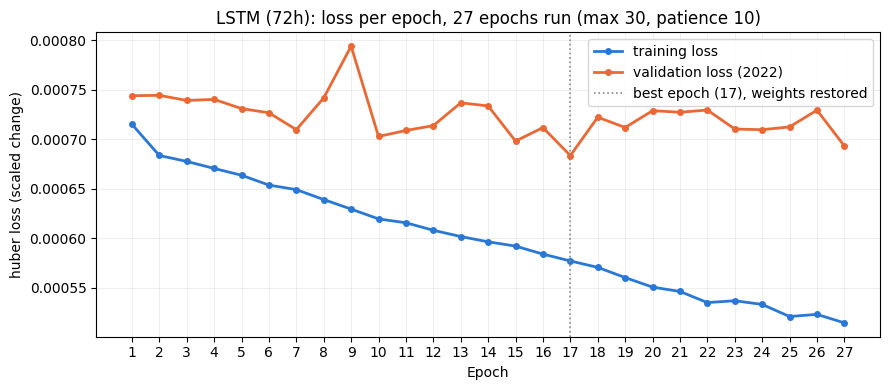

In [27]:
epochs_axis = np.arange(1, len(train_losses) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(epochs_axis, train_losses, color=C_MODEL, linewidth=2, marker="o", markersize=4, label="training loss")
ax.plot(epochs_axis, val_losses, color=C_LAST, linewidth=2, marker="o", markersize=4, label="validation loss (2022)")
ax.axvline(best_epoch, color=C_MUTED, linestyle=":", linewidth=1.2, label=f"best epoch ({best_epoch}), weights restored")
ax.set_xlabel("Epoch")
ax.set_ylabel(f"{LOSS} loss (scaled change)")
ax.set_xticks(epochs_axis)
ax.set_title(f"{MODEL_NAME}: loss per epoch, {len(train_losses)} epochs run (max {EPOCHS}, patience {PATIENCE})")
ax.grid(alpha=0.3, linewidth=0.5)
ax.legend()
plt.tight_layout()
plt.show()

## 13. Evaluation

### 13.1 Test metrics and the persistence check

The first table compares the model with the naive baselines on the test year (2024). The second reports RMSE and MAE
skill against last value on **every** partition, on identical targets. Beating persistence on training data but not
on validation or test means overfitting; failing even on training data means the model is not learning the task.

In [28]:
y_true_test, naive_test = naive["test"]
test_table = pd.DataFrame({MODEL_NAME: compute_metrics(final["test"]["y_true"], final["test"]["y_pred"]),
                           **{name: compute_metrics(y_true_test, pred) for name, pred in naive_test.items()}}
                          ).T[METRIC_COLS]
test_table.index.name = f"{HORIZON}h horizon, test {year_span(TEST_YEARS)}"
test_table.to_csv(output_path("test_metrics.csv"))
display(test_table)

skill_rows = {}
for name in ("train", "val", "test"):
    y_true, preds = naive[name]
    mod = compute_metrics(final[name]["y_true"], final[name]["y_pred"])
    last = compute_metrics(y_true, preds["Last value"])
    skill_rows[name] = {"model_RMSE": mod["RMSE"], "last_value_RMSE": last["RMSE"],
                        "RMSE_skill": 1 - mod["RMSE"] / last["RMSE"], "model_MAE": mod["MAE"],
                        "last_value_MAE": last["MAE"], "MAE_skill": 1 - mod["MAE"] / last["MAE"],
                        "model_bias": mod["Bias"], "n_targets": len(y_true)}
skill_table = pd.DataFrame(skill_rows).T
skill_table.index.name = "partition"
display(skill_table.astype({"n_targets": int}).style
        .format("{:.5f}", subset=["model_RMSE", "last_value_RMSE", "model_MAE", "last_value_MAE"])
        .format("{:+.1%}", subset=["RMSE_skill", "MAE_skill"]).format("{:+.5f}", subset=["model_bias"]))

,MSE,RMSE,MAE,MAPE,SMAPE,RSE,CORR,Bias
"72h horizon, test 2024",,,,,,,,
LSTM (72h),0.001088,0.032982,0.013691,4.043755,4.406137,0.257259,0.867401,-0.005137
Last value,0.001119,0.033446,0.017789,5.393937,5.646829,0.264552,0.867830,0.001368
Moving average (24h),0.001186,0.034434,0.019242,5.887407,6.131282,0.280409,0.858591,0.001559


,model_RMSE,last_value_RMSE,RMSE_skill,model_MAE,last_value_MAE,MAE_skill,model_bias,n_targets
partition,,,,,,,,
train,0.02530,0.02725,+7.2%,0.01064,0.01509,+29.5%,-0.00527,26207
val,0.03083,0.03261,+5.5%,0.01252,0.01638,+23.6%,-0.00636,8665
test,0.03298,0.03345,+1.4%,0.01369,0.01779,+23.0%,-0.00514,8689


### 13.2 Where the skill comes from: rain in the 72-hour gap

Windows are split by the rain that actually fell **between the window's last hour and its target** (looked up after
the fact, for scoring only; it is never an input). With no gap rain the future is forecastable: the drydown and the
post-peak recession. With gap rain, neither the model nor persistence can see it coming. A good model wins clearly
on the first group and loses little on the second.

The false-rise count checks the spike problem: windows where the model forecast a rise of more than 0.02 that did
not happen (`SWC_20` rose by less than 0.005).

In [29]:
breakdown = {}
for name in ("val", "test"):
    p, (y_true, preds) = final[name], naive[name]
    last = preds["Last value"]
    gap = GAP_RAIN.reindex(p["end_time"]).to_numpy()
    for label, mask in [(f"no gap rain (< {GAP_RAIN_MM:g} mm)", gap < GAP_RAIN_MM),
                        (f"gap rain (>= {GAP_RAIN_MM:g} mm)", gap >= GAP_RAIN_MM), ("all", np.ones(len(gap), bool))]:
        mod, lv = compute_metrics(y_true[mask], p["y_pred"][mask]), compute_metrics(y_true[mask], last[mask])
        breakdown[(name, label)] = {
            "windows": int(mask.sum()),
            "share_of_last_value_sq_error": ((y_true[mask] - last[mask]) ** 2).sum() / ((y_true - last) ** 2).sum(),
            "model_RMSE": mod["RMSE"], "last_value_RMSE": lv["RMSE"], "RMSE_skill": 1 - mod["RMSE"] / lv["RMSE"],
            "model_MAE": mod["MAE"], "last_value_MAE": lv["MAE"], "MAE_skill": 1 - mod["MAE"] / lv["MAE"],
            "model_bias": mod["Bias"], "last_value_bias": lv["Bias"]}
    forecast_rise = p["y_pred"] - last > RISE_FORECAST_MIN
    false_rise = forecast_rise & (y_true - last < RISE_ACTUAL_MAX)
    print(f"{name}: forecast rise > {RISE_FORECAST_MIN} in {forecast_rise.sum()} windows; in {false_rise.sum()} of "
          f"them SWC_20 rose by less than {RISE_ACTUAL_MAX} (false rises)")
breakdown_table = pd.DataFrame(breakdown).T
breakdown_table.index.names = ["partition", "windows by rain in the 72h gap"]
display(breakdown_table.style.format("{:.0f}", subset=["windows"])
        .format("{:.0%}", subset=["share_of_last_value_sq_error"]).format("{:+.1%}", subset=["RMSE_skill", "MAE_skill"])
        .format("{:.5f}", subset=["model_RMSE", "last_value_RMSE", "model_MAE", "last_value_MAE"])
        .format("{:+.5f}", subset=["model_bias", "last_value_bias"]))

val: forecast rise > 0.02 in 59 windows; in 41 of them SWC_20 rose by less than 0.005 (false rises)
test: forecast rise > 0.02 in 88 windows; in 74 of them SWC_20 rose by less than 0.005 (false rises)


### 13.3 Test year by month

The monthly table shows whether the skill and the bias hold all year, by target month (bias > 0 means too wet).
Then there is one panel per month, with each y-axis scaled to that month so small errors and lags stay visible. The
last-value baseline is the actual series shifted right by exactly 72 hours; where the model line sits on top of it,
the model is effectively predicting "no change".

In [30]:
t = final["test"]
assert np.allclose(t["y_true"], df.loc[t["target_time"], TARGET_COL].to_numpy())   # aligned by timestamp
assert ((t["target_time"] - t["end_time"]) == pd.Timedelta(hours=HORIZON)).all()
monthly = pd.DataFrame({"actual": t["y_true"], "model": t["y_pred"], "last_value": naive_test["Last value"]},
                       index=t["target_time"])


def month_scores(m):
    mod, lv = compute_metrics(m["actual"], m["model"]), compute_metrics(m["actual"], m["last_value"])
    return pd.Series({"model_RMSE": mod["RMSE"], "last_value_RMSE": lv["RMSE"], "model_MAE": mod["MAE"],
                      "last_value_MAE": lv["MAE"], "model_bias": mod["Bias"], "last_value_bias": lv["Bias"]})


by_month = monthly.groupby(monthly.index.to_period("M")).apply(month_scores)
by_month["model_better_MAE"] = by_month["model_MAE"] < by_month["last_value_MAE"]
by_month.index.name = "target month"
display(by_month.style.format("{:.4f}", subset=["model_RMSE", "last_value_RMSE", "model_MAE", "last_value_MAE"])
        .format("{:+.4f}", subset=["model_bias", "last_value_bias"]))

,model_RMSE,last_value_RMSE,model_MAE,last_value_MAE,model_bias,last_value_bias,model_better_MAE
target month,,,,,,,
2024-01,0.0172,0.0190,0.0121,0.0139,-0.0027,+0.0010,True
2024-02,0.0129,0.0157,0.0090,0.0113,-0.0005,+0.0021,True
2024-03,0.0054,0.0091,0.0042,0.0070,+0.0020,+0.0065,True
2024-04,0.0160,0.0154,0.0099,0.0099,-0.0043,-0.0031,False
2024-05,0.0357,0.0367,0.0211,0.0248,-0.0106,-0.0007,True
2024-06,0.0582,0.0597,0.0321,0.0434,-0.0147,-0.0010,True
2024-07,0.0609,0.0571,0.0374,0.0451,-0.0250,-0.0049,True
2024-08,0.0067,0.0162,0.0057,0.0143,+0.0057,+0.0143,True
2024-09,0.0616,0.0631,0.0259,0.0359,-0.0132,-0.0019,True


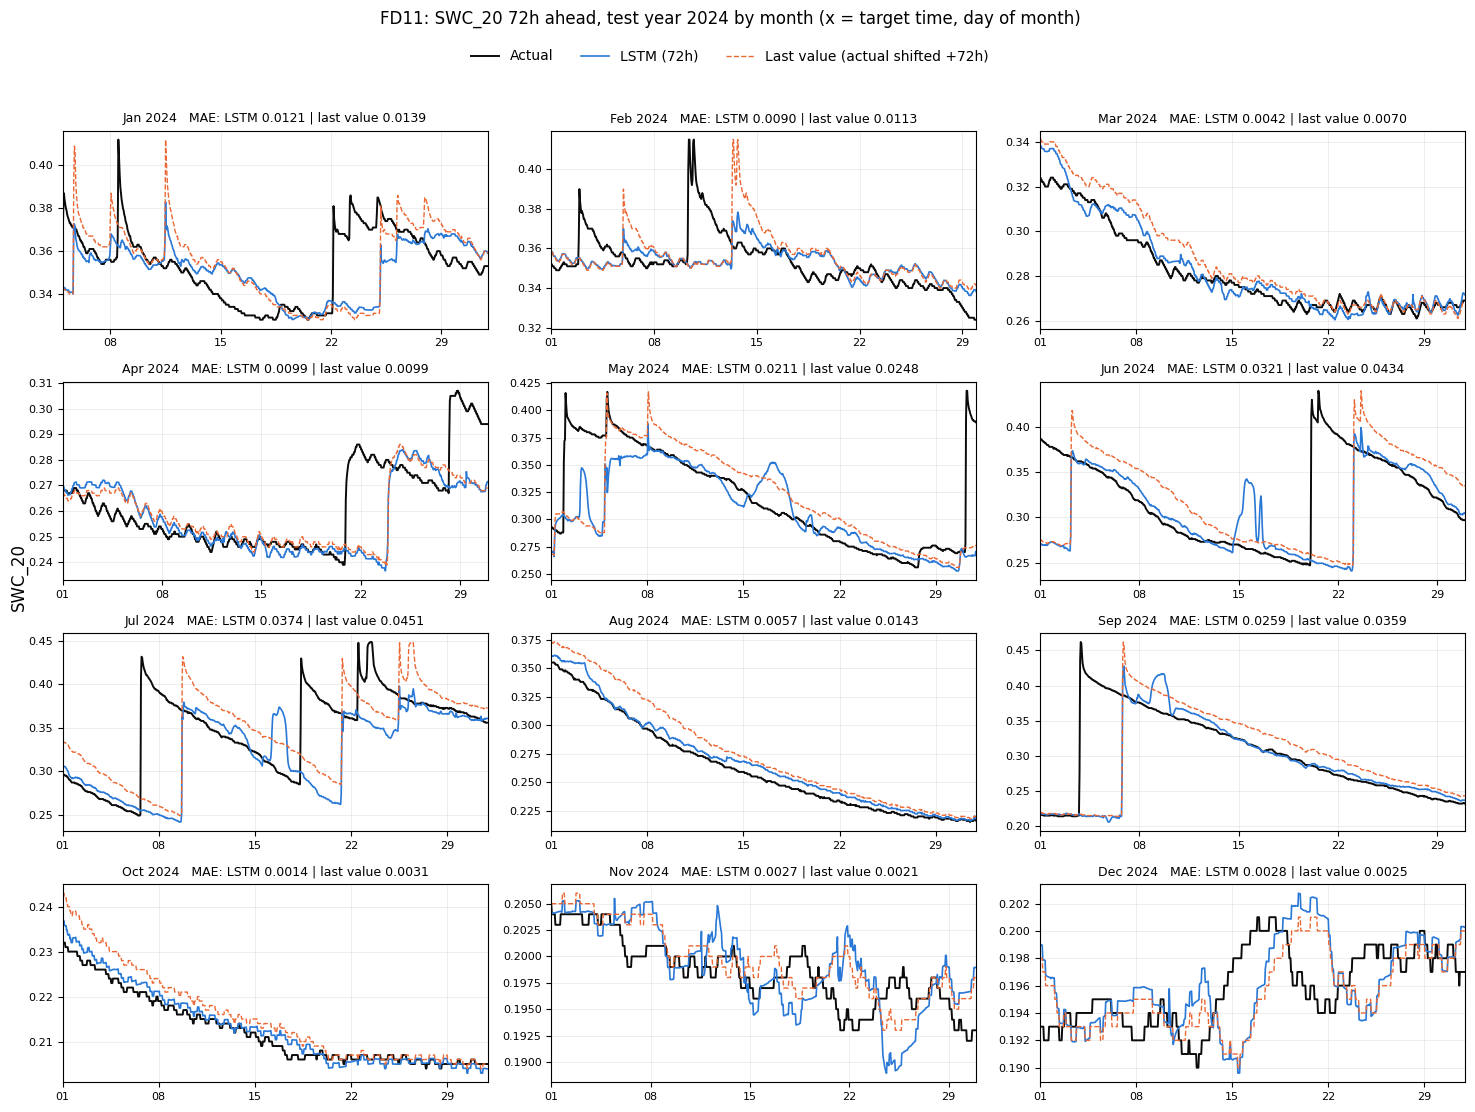

In [31]:
months = monthly.index.to_period("M").unique()
ncols = 3
nrows = int(np.ceil(len(months) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 2.7 * nrows), squeeze=False)
for ax, month in zip(axes.flat, months):
    m = monthly[monthly.index.to_period("M") == month]
    ax.plot(m.index, m["actual"], color=C_ACTUAL, linewidth=1.4, label="Actual")
    ax.plot(m.index, m["model"], color=C_MODEL, linewidth=1.2, label=MODEL_NAME)
    ax.plot(m.index, m["last_value"], color=C_LAST, linewidth=1.0, linestyle="--",
            label=f"Last value (actual shifted +{HORIZON}h)")
    ax.set_title(f"{month.strftime('%b %Y')}   MAE: LSTM {by_month.loc[month, 'model_MAE']:.4f} | "
                 f"last value {by_month.loc[month, 'last_value_MAE']:.4f}", fontsize=9)
    ax.set_xlim(m.index.min(), m.index.max())
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22, 29]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3, linewidth=0.5)
for ax in axes.flat[len(months):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"{STATION}: SWC_20 {HORIZON}h ahead, test year {year_span(TEST_YEARS)} by month "
             f"(x = target time, day of month)", y=1.025)
fig.supylabel("SWC_20")
plt.tight_layout(rect=(0, 0, 1, 0.975))
plt.show()

In [32]:
with open(output_path("run_summary.json"), "w") as f:
    json.dump({"station": STATION, "horizon": HORIZON, "window": WINDOW_SIZE, "train_years": TRAIN_YEARS,
               "val_years": VAL_YEARS, "test_years": TEST_YEARS, "skipped_years": SKIPPED_YEARS,
               "gauge_outage": [str(outage_start), str(outage_end)], "features": FEATURES,
               "ppt_deadband_mm": PPT_DEADBAND_MM, "loss": LOSS, "huber_delta": HUBER_DELTA,
               "model_config": MODEL_CONFIG, "max_epochs": EPOCHS, "patience": PATIENCE,
               "best_epoch": best_epoch, "epochs_run": len(train_losses), "cv_fold_years": CV_FOLD_YEARS,
               "test_RMSE_skill": float(skill_table.loc["test", "RMSE_skill"]),
               "test_MAE_skill": float(skill_table.loc["test", "MAE_skill"])}, f, indent=2)
print("Saved to", OUTPUT_DIR)

Saved to outputs_lstm_72h
